169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 2094s 12us/step
Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.0776 - loss: 3.9531 - val_accuracy: 0.0960 - val_loss: 2.9571
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1629 - loss: 2.7129 - val_accuracy: 0.1520 - val_loss: 2.7946
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1951 - loss: 2.5796 - val_accuracy: 0.1800 - val_loss: 2.6620
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2258 - loss: 2.4871 - val_accuracy: 0.1940 - val_loss: 2.6036
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2529 - loss: 2.4124 - val_accuracy: 0.2160 - val_loss: 2.5630
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2744 - loss: 2.3365 - val_accuracy: 0.2120 - val_loss: 2.5725
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2933 - loss: 2.2685 - val_accuracy: 0.2040 - val_loss: 2.5968
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy

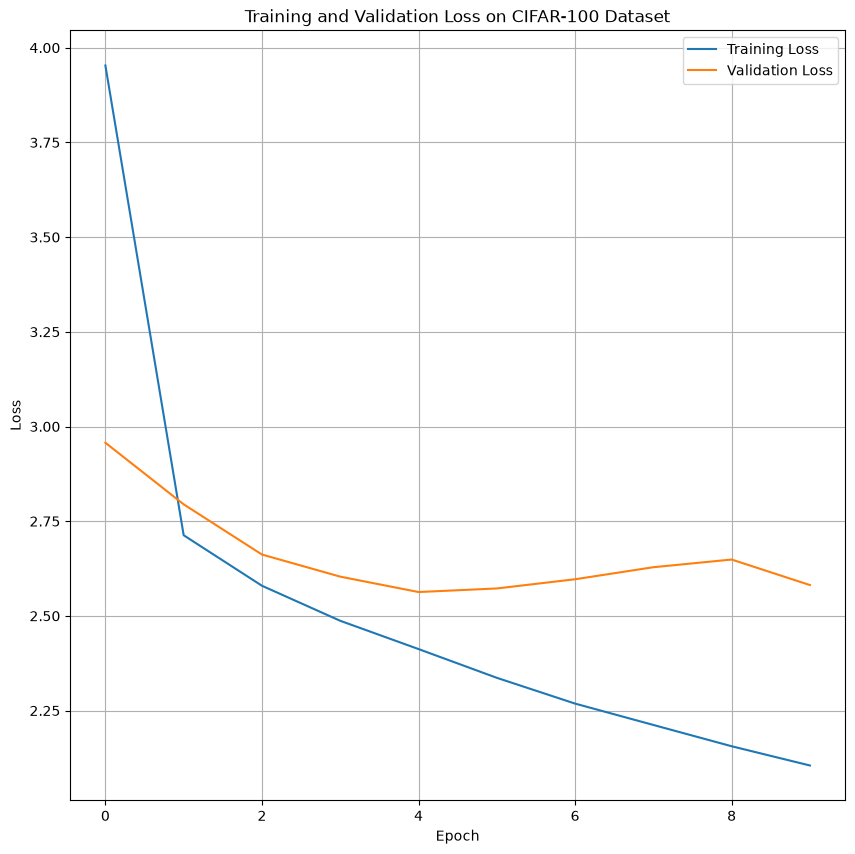

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

# set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# load training and test data from CIFAR-100 dataset using superclass categories
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar100.load_data(label_mode='coarse')

# select only the first 5000 training samples
(X_train,
 y_train) = (X_train[:5000],
             y_train[:5000])

# select only the first 1000 test samples
(X_test,
 y_test) = (X_test[:1000],
            y_test[:1000])

# normalize pixel values from [0, 255] to [0, 1]
(X_train,
 X_test) = (X_train / 255.0,
            X_test / 255.0)

# build neural network with four hidden layers
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Flatten(), # convert to 1D

    # four hidden layers with 256 neurons each, using ELU and HE normal initialization
    tf.keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),
    tf.keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),
    tf.keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),
    tf.keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),

    # output layer with one neuron for each of the 20 categories
    tf.keras.layers.Dense(20, activation="softmax")
])

# configure Nadam optimizer with a learning rate of 0.001
optimizer = tf.keras.optimizers.Nadam(learning_rate=0.001)

# compile model with Nadam optimizer, loss function and accuracy metric
model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ensures that training is stopped if validation loss does not improve for 5 consecutive epochs,
# and restores the best weights
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# fit the model using 10% of training data as validation
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop]
)

# evaluate model on test data and report accuracy in percentage
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(10, 10))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss on CIFAR-100 Dataset")
plt.legend()
plt.grid(True)
plt.show()
